# Fakeddit Research EDA

This notebook summarizes the current research-stage analysis for a multimodal fake news detection project using the Fakeddit dataset.

The goal here is **not** to train a production model yet. The goal is to understand the dataset, validate split quality, inspect label balance, identify missingness and leakage risks, and prepare a clean foundation for later text-only, image-only, and multimodal experiments.

## Research Questions

1. How large are the full and multimodal-only Fakeddit splits?
2. Are the labels balanced enough for baseline experiments?
3. Is `clean_title` usable as the primary text input?
4. How complete are image URLs and image flags?
5. Are there obvious split leakage risks such as duplicate IDs, repeated titles, or reused image URLs?
6. Which source, subreddit, and metadata patterns should be treated carefully in later experiments?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "reports" / "fakeddit" / "deep_eda").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORT_DIR = PROJECT_ROOT / "reports" / "fakeddit" / "deep_eda"
FIGURE_DIR = REPORT_DIR / "figures"

assert REPORT_DIR.exists(), f"Missing report directory: {REPORT_DIR}"
REPORT_DIR

PosixPath('/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda')

## Load EDA Artifacts

The notebook uses generated CSV artifacts so the analysis is reproducible and fast to rerun during research meetings. The raw TSVs remain under `data/raw/fakeddit/`.

In [2]:
dataset_summary = pd.read_csv(REPORT_DIR / "dataset_summary.csv")
label_distribution = pd.read_csv(REPORT_DIR / "label_distribution.csv")
missingness = pd.read_csv(REPORT_DIR / "missingness.csv")
duplicate_titles = pd.read_csv(REPORT_DIR / "duplicate_clean_titles_across_splits.csv")
id_overlap = pd.read_csv(REPORT_DIR / "id_overlap_across_splits.csv")
image_url_overlap = pd.read_csv(REPORT_DIR / "image_url_overlap_across_splits.csv")
top_subreddit = pd.read_csv(REPORT_DIR / "top_subreddit.csv")
top_domain = pd.read_csv(REPORT_DIR / "top_domain.csv")
top_author = pd.read_csv(REPORT_DIR / "top_author.csv")

print("Loaded tables:")
for name, frame in {
    "dataset_summary": dataset_summary,
    "label_distribution": label_distribution,
    "missingness": missingness,
    "duplicate_titles": duplicate_titles,
    "id_overlap": id_overlap,
    "image_url_overlap": image_url_overlap,
    "top_subreddit": top_subreddit,
    "top_domain": top_domain,
    "top_author": top_author,
}.items():
    print(f"- {name}: {frame.shape[0]:,} rows x {frame.shape[1]:,} columns")

Loaded tables:
- dataset_summary: 6 rows x 36 columns
- label_distribution: 66 rows x 7 columns
- missingness: 96 rows x 5 columns
- duplicate_titles: 200 rows x 6 columns
- id_overlap: 0 rows x 6 columns
- image_url_overlap: 200 rows x 6 columns
- top_subreddit: 131 rows x 6 columns
- top_domain: 150 rows x 6 columns
- top_author: 150 rows x 6 columns


## Dataset Size and Coverage

The original Fakeddit release includes both broad splits and multimodal-only splits. For results comparable to the original paper, the multimodal-only splits are the most important because every row has text and is intended to have an image.

In [3]:
summary_cols = [
    "subset",
    "split",
    "rows",
    "unique_ids",
    "missing_clean_title_rows",
    "has_image_rows",
    "image_url_rows",
    "distinct_subreddits",
    "distinct_domains",
]
summary_view = dataset_summary[summary_cols].copy()
summary_view["image_url_share"] = summary_view["image_url_rows"] / summary_view["rows"]
summary_view["missing_clean_title_share"] = summary_view["missing_clean_title_rows"] / summary_view["rows"]
summary_view.style.format({
    "rows": "{:,}",
    "unique_ids": "{:,}",
    "missing_clean_title_rows": "{:,}",
    "has_image_rows": "{:,}",
    "image_url_rows": "{:,}",
    "distinct_subreddits": "{:,}",
    "distinct_domains": "{:,}",
    "image_url_share": "{:.2%}",
    "missing_clean_title_share": "{:.2%}",
})

,subset,split,rows,unique_ids,missing_clean_title_rows,has_image_rows,image_url_rows,distinct_subreddits,distinct_domains,image_url_share,missing_clean_title_share
0,all_samples,test,"92,444","92,444","7,963","67,255","67,099",22,"5,073",72.58%,8.61%
1,all_samples,train,"878,218","878,218","75,429","639,101","637,564",22,"20,633",72.60%,8.59%
2,all_samples,validate,"92,444","92,444","7,908","67,208","67,035",22,"5,108",72.51%,8.55%
3,multimodal_only,test,"59,319","59,319",0,"59,319","59,163",21,"2,735",99.74%,0.00%
4,multimodal_only,train,"564,000","564,000",0,"564,000","562,466",22,"10,821",99.73%,0.00%
5,multimodal_only,validate,"59,342","59,342",0,"59,342","59,169",22,"2,713",99.71%,0.00%


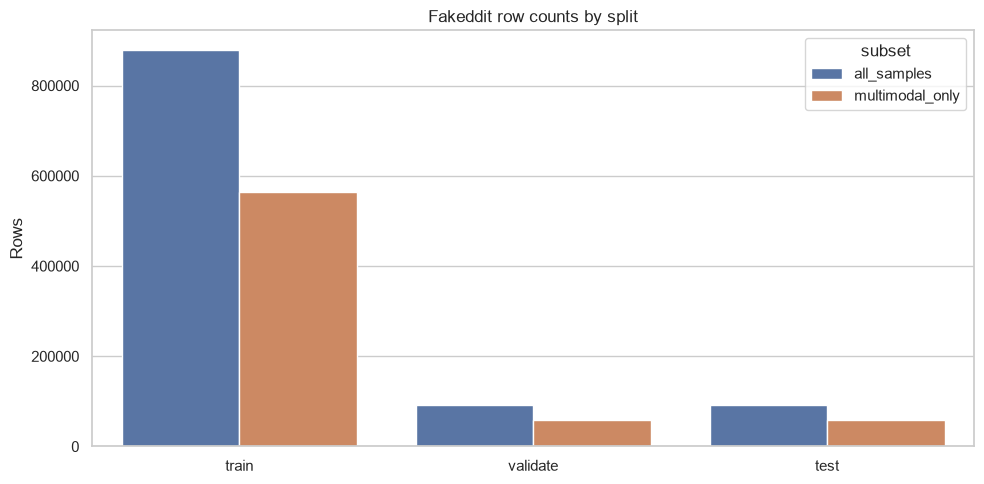

In [4]:
plt.figure(figsize=(10, 5))
plot_data = dataset_summary.copy()
plot_data["split"] = pd.Categorical(plot_data["split"], ["train", "validate", "test"], ordered=True)
sns.barplot(data=plot_data, x="split", y="rows", hue="subset")
plt.title("Fakeddit row counts by split")
plt.ylabel("Rows")
plt.xlabel("")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

### Observation

The multimodal-only train split has **564,000 rows**, which is enough for meaningful later baselines. The broad train split has **878,218 rows**, but it includes non-image rows and missing text rows, so it should not be mixed blindly with multimodal experiments.

## Label Balance

Fakeddit provides 2-way, 3-way, and 6-way labels. The 2-way label is useful for first baselines; the 6-way label is more fine-grained and should be handled with extra care because class imbalance is stronger.

In [5]:
two_way = label_distribution[label_distribution["label_column"] == "2_way_label"].copy()
two_way["share_pct"] = two_way["share"] * 100
two_way[["subset", "split", "label_name", "rows", "share_pct"]].style.format({
    "rows": "{:,}",
    "share_pct": "{:.2f}%",
})

,subset,split,label_name,rows,share_pct
0,all_samples,test,true,"50,100",54.19%
1,all_samples,test,fake,"42,344",45.81%
11,all_samples,train,true,"477,785",54.40%
12,all_samples,train,fake,"400,433",45.60%
22,all_samples,validate,true,"50,304",54.42%
23,all_samples,validate,fake,"42,140",45.58%
33,multimodal_only,test,true,"35,812",60.37%
34,multimodal_only,test,fake,"23,507",39.63%
44,multimodal_only,train,true,"341,919",60.62%
45,multimodal_only,train,fake,"222,081",39.38%


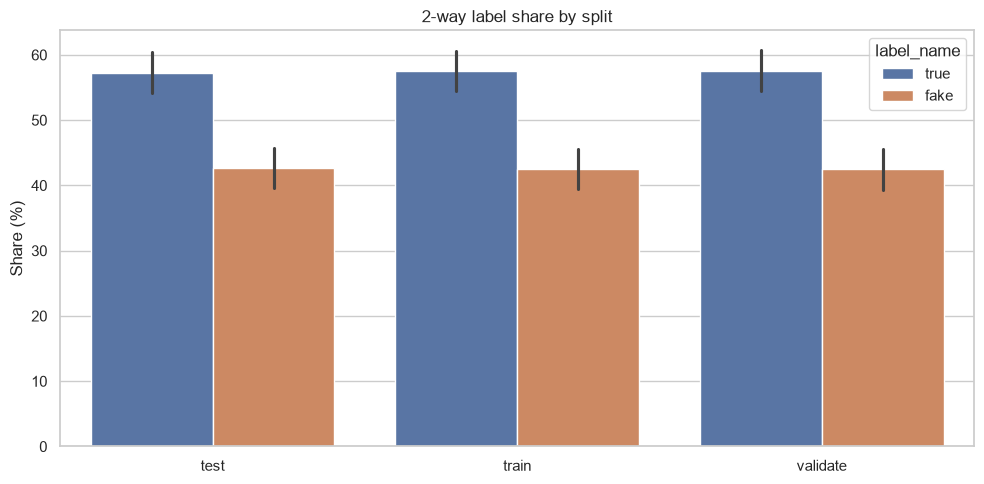

In [6]:
plt.figure(figsize=(10, 5))
sns.barplot(data=two_way, x="split", y="share_pct", hue="label_name")
plt.title("2-way label share by split")
plt.ylabel("Share (%)")
plt.xlabel("")
plt.tight_layout()
plt.show()

In [7]:
six_way = label_distribution[label_distribution["label_column"] == "6_way_label"].copy()
six_way["share_pct"] = six_way["share"] * 100
six_way_pivot = six_way.pivot_table(
    index=["subset", "split"],
    columns="label_name",
    values="share_pct",
    fill_value=0,
).reset_index()
six_way_pivot.style.format({col: "{:.2f}%" for col in six_way_pivot.columns if col not in {"subset", "split"}})

label_name,subset,split,false connection,imposter,manipulated content,misleading,satire/parody,true
0,all_samples,test,27.38%,2.68%,3.07%,16.25%,4.81%,45.81%
1,all_samples,train,27.57%,2.71%,3.03%,16.28%,4.82%,45.60%
2,all_samples,validate,27.68%,2.72%,2.90%,16.30%,4.82%,45.58%
3,multimodal_only,test,29.45%,2.06%,3.89%,19.04%,5.92%,39.63%
4,multimodal_only,train,29.76%,2.09%,3.83%,19.01%,5.94%,39.38%
5,multimodal_only,validate,30.01%,2.09%,3.67%,19.00%,5.93%,39.30%


### Observation

The multimodal-only 2-way splits are consistently around **60% true / 40% fake**. This is workable, but evaluation should report more than accuracy, especially macro F1 and per-class metrics.

## Text Field Quality

The Fakeddit README recommends `clean_title` as the cleaned textual input. This section checks missingness and text length patterns.

In [8]:
text_cols = [
    "subset",
    "split",
    "clean_title_chars_mean",
    "clean_title_chars_median",
    "clean_title_chars_p95",
    "clean_title_words_mean",
    "clean_title_words_median",
    "clean_title_words_p95",
]
dataset_summary[text_cols].round(2)

,subset,split,clean_title_chars_mean,clean_title_chars_median,clean_title_chars_p95,clean_title_words_mean,clean_title_words_median,clean_title_words_p95
0,all_samples,test,41.95,36.0,99.0,7.40,6.0,18.0
1,all_samples,train,41.92,36.0,98.0,7.40,7.0,17.0
2,all_samples,validate,41.91,36.0,99.0,7.39,6.0,17.0
3,multimodal_only,test,41.99,35.0,97.0,7.46,6.0,17.0
4,multimodal_only,train,41.93,34.0,96.0,7.46,6.0,17.0
5,multimodal_only,validate,41.73,34.0,96.0,7.42,6.0,17.0


In [9]:
img_path = FIGURE_DIR / "clean_title_length_distribution.png"
display(Markdown(f"![Clean title length distribution]({img_path.as_posix()})"))

![Clean title length distribution](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/clean_title_length_distribution.png)

### Observation

`clean_title` is short: median length is roughly **34-36 characters** or **6-7 words**. Text-only models will be working with headline-like snippets, not long articles. This makes source/domain signals and visual context especially important in later multimodal work.

## Missingness

This section focuses on fields that are likely to affect modeling: text, image URLs, comments/upvotes, and linked submissions.

In [10]:
focus_columns = ["clean_title", "image_url", "linked_submission_id", "num_comments", "upvote_ratio"]
missing_focus = missingness[missingness["column"].isin(focus_columns)].copy()
missing_focus["missing_pct"] = missing_focus["missing_share"] * 100
missing_focus.sort_values(["subset", "split", "missing_pct"], ascending=[True, True, False])[
    ["subset", "split", "column", "missing_rows", "missing_pct"]
].style.format({"missing_rows": "{:,}", "missing_pct": "{:.2f}%"})

,subset,split,column,missing_rows,missing_pct
7,all_samples,test,linked_submission_id,"67,133",72.62%
6,all_samples,test,image_url,"25,345",27.42%
8,all_samples,test,num_comments,"25,311",27.38%
12,all_samples,test,upvote_ratio,"25,311",27.38%
1,all_samples,test,clean_title,"7,963",8.61%
23,all_samples,train,linked_submission_id,"636,118",72.43%
24,all_samples,train,num_comments,"242,100",27.57%
28,all_samples,train,upvote_ratio,"242,100",27.57%
22,all_samples,train,image_url,"240,654",27.40%
17,all_samples,train,clean_title,"75,429",8.59%


### Observation

The multimodal-only files have no missing `clean_title`, and image URLs are present for more than **99.7%** of rows. However, older Reddit image URLs can fail during download, so image availability must be measured after download, not assumed from `hasImage` alone.

## Source and Community Patterns

Fakeddit is not a random sample of the open web. Subreddit and domain distributions are concentrated, which can create shortcuts for models.

In [11]:
def show_top(table, subset="multimodal_only", split="train", n=15):
    view = table[(table["subset"] == subset) & (table["split"] == split)].copy().head(n)
    view["share_pct"] = view["share"] * 100
    return view[["value", "rows", "share_pct"]].style.format({"rows": "{:,}", "share_pct": "{:.2f}%"})

show_top(top_subreddit, subset="multimodal_only", split="train", n=15)

,value,rows,share_pct
87,psbattle_artwork,"167,857",29.76%
88,mildlyinteresting,"86,237",15.29%
89,photoshopbattles,"55,198",9.79%
90,pareidolia,"47,331",8.39%
91,fakehistoryporn,"35,576",6.31%
92,nottheonion,"31,977",5.67%
93,upliftingnews,"23,960",4.25%
94,fakealbumcovers,"21,725",3.85%
95,misleadingthumbnails,"15,962",2.83%
96,propagandaposters,"13,848",2.46%


In [12]:
show_top(top_domain, subset="multimodal_only", split="train", n=15)

,value,rows,share_pct
100,i.redd.it,"176,260",31.25%
101,,"167,857",29.76%
102,i.imgur.com,"74,782",13.26%
103,imgur.com,"29,656",5.26%
104,i.reddituploads.com,"3,997",0.71%
105,theonion.com,"3,714",0.66%
106,archive.is,"3,198",0.57%
107,clickhole.com,"2,507",0.44%
108,reuters.com,"2,282",0.40%
109,web.archive.org,"2,277",0.40%


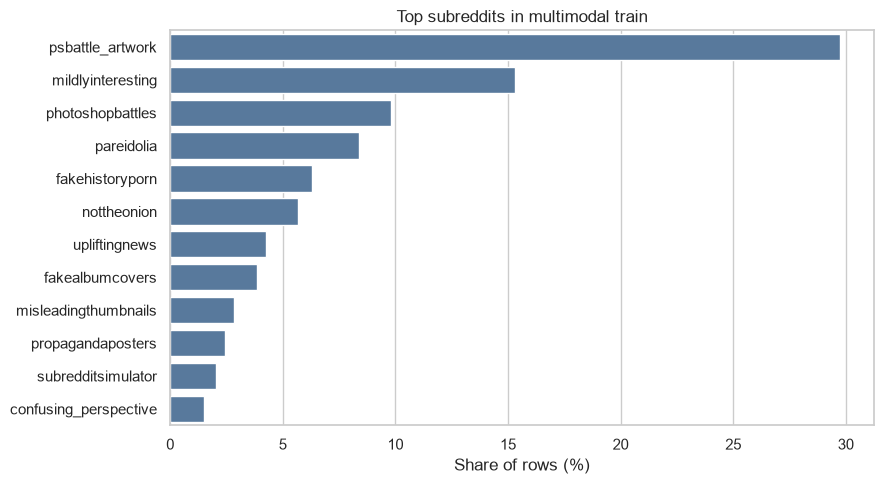

In [13]:
plot_top = top_subreddit[(top_subreddit["subset"] == "multimodal_only") & (top_subreddit["split"] == "train")].head(12).copy()
plot_top["share_pct"] = plot_top["share"] * 100
plt.figure(figsize=(9, 5))
sns.barplot(data=plot_top, y="value", x="share_pct", color="#4c78a8")
plt.title("Top subreddits in multimodal train")
plt.xlabel("Share of rows (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Observation

Subreddit/domain concentration is a serious research consideration. A high-performing model could learn dataset-specific community or source shortcuts instead of robust misinformation evidence. Later experiments should include ablations with and without metadata/source features.

## Leakage and Split Integrity

This section checks exact ID overlap, repeated clean titles, and repeated image URLs across train/validation/test.

In [14]:
print(f"Cross-split ID overlaps within comparable subsets: {len(id_overlap):,}")
id_overlap.head()

Cross-split ID overlaps within comparable subsets: 0


,subset,column,value,rows,splits,split_count


In [15]:
duplicate_titles.head(20).style.format({"rows": "{:,}", "unique_ids": "{:,}"})

,subset,clean_title_norm,rows,unique_ids,splits,split_count
0,all_samples,other discussions,"9,264","9,264","test,train,validate",3
1,all_samples,cutouts,"8,000","8,000","test,train,validate",3
2,all_samples,available here,"2,421","2,421","test,train,validate",3
3,all_samples,imgur,"1,684","1,684","test,train,validate",3
4,all_samples,this,764,764,"test,train,validate",3
5,all_samples,obligatory,453,453,"test,train,validate",3
6,all_samples,nsfw,422,422,"test,train,validate",3
7,all_samples,fixed,400,400,"test,train,validate",3
8,all_samples,d,292,292,"test,train,validate",3
9,all_samples,here you go,261,261,"test,train,validate",3


In [16]:
image_url_overlap.head(20).style.format({"rows": "{:,}"})

,subset,column,value,rows,splits,split_count
0,all_samples,image_url,https://external-preview.redd.it/ESPM-tTuK3werLgfWG_wBsw_trUSDNU4bI5s2jVRAgQ.png?width=108&crop=smart&auto=webp&s=6bdf4d9c8ec6b3100f803c1cf0848f49a5aee344,"2,981","test,train,validate",3
1,all_samples,image_url,https://external-preview.redd.it/JE5v1BJsIlc2DiVs1rwqi6CLE49u9lcH1SVOoMRTF3k.jpg?width=320&crop=smart&auto=webp&s=b3d81215eab9b3b229e6ffd236587b1513734be9,425,"test,train,validate",3
2,all_samples,image_url,https://external-preview.redd.it/rw3C157-mb0CTpawp_iy2QUuOWtOs9AaKwKVk8JT52w.jpg?width=108&crop=smart&auto=webp&s=13f10bd79b14373c26cda336f47e723faa67d7a9,305,"test,train,validate",3
3,all_samples,image_url,https://external-preview.redd.it/FUQYbH92hUUaXCQoy7XlxfEVH-efilnwLJTPLhl1cZE.jpg?width=216&crop=smart&auto=webp&s=8f01e412e3fae763bca97ccf16e1236ac8932f0f,260,"test,train,validate",3
4,all_samples,image_url,https://external-preview.redd.it/TpYwgZl_YAu-BVWDwCP4lSt8o3uqYqsdOLy4qm3_zjw.jpg?width=320&crop=smart&auto=webp&s=9c5b27e1b5a4374f226391f2feb2270404ee1b12,243,"test,train,validate",3
5,all_samples,image_url,https://external-preview.redd.it/D_OE3MNJ9mu28Ix4mkZXDvR9mRFh3w0KaFqkRxHEc68.jpg?width=320&crop=smart&auto=webp&s=5a64bca0a6699b62c516d7a099f3cd019d1a5ceb,240,"test,train,validate",3
6,all_samples,image_url,https://external-preview.redd.it/K9a5X4oJnk8_o2dlWwf24fM0oHFEudF16sF4LLH1RGU.jpg?width=320&crop=smart&auto=webp&s=875f65d95f73dc64b6a510921d3ede7cc8ecd6d2,200,"test,train,validate",3
7,all_samples,image_url,https://external-preview.redd.it/t0otWoPoXX6bgb9MAYZLlSUwu76I1IOWdXjMYgoqPd4.jpg?width=320&crop=smart&auto=webp&s=5787c2470e9f4a9805586069ccadf9dfd750b781,172,"test,train,validate",3
8,all_samples,image_url,https://external-preview.redd.it/jyVqfIPG4_Ae6mXEWd4LR1KDBYOaMMnNopNKUPMUw-8.jpg?width=320&crop=smart&auto=webp&s=6ef45ca247f6d39042fa6181e1092ce278a95491,169,"test,train,validate",3
9,all_samples,image_url,https://external-preview.redd.it/3hPWkCPHtgqmBs5VgVi86KZxuguBfT5xerMPgPL__gg.jpg?width=320&crop=smart&auto=webp&s=a6e502ef5053446c8cf318781394f726d98722de,162,"test,train,validate",3


### Observation

There is **no cross-split ID overlap** within comparable subsets, which is good. However, exact repeated `clean_title` values and repeated `image_url` values exist across splits. Some titles are generic placeholders, while repeated URLs may indicate actual image reuse. This should be investigated before publishing image-only or multimodal results.

## Recommended Research Next Steps

1. Build a clean multimodal manifest from `multimodal_only_samples`, using `id`, `clean_title`, labels, and downloaded image path.
2. Download images incrementally and record failed URLs separately.
3. Add image-level validation: dimensions, corrupted files, duplicate hashes, and perceptual hashes.
4. Establish text-only baselines first using `clean_title` only.
5. Add source/domain ablations to measure shortcut learning.
6. Only after the dataset audit, move to image-only and multimodal baselines.

## Image EDA

This section extends the existing metadata/text EDA with local downloaded-image analysis. It does **not** train a model. It reads generated image EDA artifacts from `reports/fakeddit/deep_eda/` and the row-level image manifest from `data/processed/fakeddit/image_manifest.parquet`.

Important context: only the currently downloaded local images can be validated, hashed, and plotted. The manifest still tracks every expected multimodal row, so missing-image coverage is explicit rather than assumed.

### 1. Local Image Coverage

This table compares expected multimodal rows against local files discovered by Fakeddit ID across train, validation, and test.

In [17]:
IMAGE_REPORT_DIR = REPORT_DIR
IMAGE_FIGURE_DIR = IMAGE_REPORT_DIR / "figures" / "images"
IMAGE_MANIFEST_PATH = PROJECT_ROOT / "data" / "processed" / "fakeddit" / "image_manifest.parquet"

image_manifest = pd.read_parquet(IMAGE_MANIFEST_PATH)
image_summary = pd.read_csv(IMAGE_REPORT_DIR / "image_summary.csv")
image_availability_by_label = pd.read_csv(IMAGE_REPORT_DIR / "image_availability_by_label.csv")
image_validation_failures = pd.read_csv(IMAGE_REPORT_DIR / "image_validation_failures.csv")
exact_image_duplicates = pd.read_csv(IMAGE_REPORT_DIR / "exact_image_duplicates.csv")
perceptual_image_duplicates = pd.read_csv(IMAGE_REPORT_DIR / "perceptual_image_duplicates.csv")
image_leakage_summary = pd.read_csv(IMAGE_REPORT_DIR / "image_leakage_summary.csv")
image_text_reuse_patterns = pd.read_csv(IMAGE_REPORT_DIR / "image_text_reuse_patterns.csv")

image_summary.style.format({
    "expected_multimodal_rows": "{:,}",
    "rows_with_image_url": "{:,}",
    "locally_downloaded_images": "{:,}",
    "valid_images": "{:,}",
    "missing_images": "{:,}",
    "corrupted_images": "{:,}",
    "coverage_pct": "{:.4f}%",
    "valid_coverage_pct": "{:.4f}%",
})

,split,expected_multimodal_rows,rows_with_image_url,locally_downloaded_images,valid_images,missing_images,corrupted_images,coverage_pct,valid_coverage_pct
0,train,"564,000","562,466","2,846","2,846","561,154",0,0.5046%,0.5046%
1,validate,"59,342","59,169",958,957,"58,384",1,1.6144%,1.6127%
2,test,"59,319","59,163",947,947,"58,372",0,1.5965%,1.5965%


In [18]:
image_availability_by_label.style.format({
    "expected": "{:,}",
    "downloaded": "{:,}",
    "valid": "{:,}",
    "missing": "{:,}",
    "download_coverage_pct": "{:.4f}%",
    "valid_coverage_pct": "{:.4f}%",
})

,split,2_way_label,expected,downloaded,valid,missing,download_coverage_pct,valid_coverage_pct
0,train,0,"341,919","1,712","1,712","340,207",0.5007%,0.5007%
1,train,1,"222,081","1,134","1,134","220,947",0.5106%,0.5106%
2,validate,0,"36,022",578,577,"35,444",1.6046%,1.6018%
3,validate,1,"23,320",380,380,"22,940",1.6295%,1.6295%
4,test,0,"35,812",565,565,"35,247",1.5777%,1.5777%
5,test,1,"23,507",382,382,"23,125",1.6250%,1.6250%


### 2. Image Validation

The scanner uses Pillow to verify local files and records zero-byte files, HTML/error responses, unreadable images, unsupported formats, and corrupt/truncated files. Failed files are reported but never deleted automatically.

In [19]:
print(f"Downloaded local images: {int(image_manifest['downloaded'].sum()):,}")
print(f"Valid local images: {int(image_manifest['valid_image'].sum()):,}")
print(f"Validation failures: {len(image_validation_failures):,}")
image_validation_failures.head(20)

Downloaded local images: 4,751
Valid local images: 4,750
Validation failures: 1


,id,split,path,image_url,error_type,error_message
0,ds4mu90,validate,/Users/aka_ank/Desktop/FNEWS/data/raw/fakeddit/images/ds4mu90.jpg,https://www.dropbox.com/s/daxolsm5aw9zgzt/ET%20and%20Elliot%20Bike%20Crate.jpg,html_response,File starts with HTML


### 3. Formats and Color Modes

Format and color mode can become non-semantic shortcuts if they correlate with labels or splits. At this stage, the local sample is too small for strong claims, but the pipeline records these fields for the full image set once downloaded.

In [20]:
valid_images = image_manifest[image_manifest["valid_image"]].copy()
if valid_images.empty:
    display(Markdown("No valid local images are available yet."))
else:
    display(valid_images["image_format"].value_counts().rename_axis("format").reset_index(name="images"))
    display(valid_images["image_mode"].value_counts().rename_axis("mode").reset_index(name="images"))

,format,images
0,JPEG,4427
1,PNG,320
2,WEBP,2
3,GIF,1


,mode,images
0,RGB,4419
1,P,316
2,L,12
3,RGBA,3


In [21]:
for filename in ["format_distribution.png", "mode_distribution.png"]:
    image_path = IMAGE_FIGURE_DIR / filename
    if image_path.exists():
        display(Markdown(f"![{filename}]({image_path.as_posix()})"))

![format_distribution.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/format_distribution.png)

![mode_distribution.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/mode_distribution.png)

### 4. Resolution and Aspect Ratio

The scanner records width, height, pixel count, and aspect ratio for every valid local image.

In [22]:
resolution_cols = ["width", "height", "aspect_ratio", "pixel_count"]
if valid_images.empty:
    display(Markdown("No valid images to summarize."))
else:
    display(valid_images[resolution_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(3))
    small_counts = {
        "width_lt_100": int((valid_images["width"] < 100).sum()),
        "height_lt_100": int((valid_images["height"] < 100).sum()),
        "both_dimensions_lt_224": int(((valid_images["width"] < 224) & (valid_images["height"] < 224)).sum()),
        "pixel_count_gt_1mp": int((valid_images["pixel_count"] > 1_000_000).sum()),
    }
    display(pd.DataFrame([small_counts]))

,width,height,aspect_ratio,pixel_count
count,4750.000,4750.000,4750.000,4.750000e+03
mean,571.009,495.444,1.264,5.118842e+05
std,561.919,471.384,0.483,1.323816e+06
min,90.000,35.000,0.221,3.780000e+03
25%,320.000,213.000,0.751,6.816000e+04
50%,320.000,380.500,1.333,1.280000e+05
75%,600.000,568.000,1.600,3.320640e+05
95%,1809.200,1346.100,1.927,2.160000e+06
99%,3000.000,2575.120,2.294,7.298974e+06
max,5616.000,4724.000,8.000,2.102630e+07


,width_lt_100,height_lt_100,both_dimensions_lt_224,pixel_count_gt_1mp
0,1,128,170,522


In [23]:
for filename in [
    "width_distribution.png",
    "height_distribution.png",
    "aspect_ratio_distribution.png",
    "pixel_count_distribution.png",
]:
    image_path = IMAGE_FIGURE_DIR / filename
    if image_path.exists():
        display(Markdown(f"![{filename}]({image_path.as_posix()})"))

![width_distribution.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/width_distribution.png)

![height_distribution.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/height_distribution.png)

![aspect_ratio_distribution.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/aspect_ratio_distribution.png)

![pixel_count_distribution.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/pixel_count_distribution.png)

### 5. File Size

File size can reveal failed downloads and may also act as a dataset shortcut if it differs by label or source.

In [24]:
if valid_images.empty:
    display(Markdown("No valid images to summarize."))
else:
    display(valid_images[["file_size_bytes", "file_size_kb"]].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(3))
    display(valid_images.nsmallest(min(10, len(valid_images)), "file_size_bytes")[["id", "split", "2_way_label", "file_size_kb", "width", "height", "valid_image"]])
    display(valid_images.nlargest(min(10, len(valid_images)), "file_size_bytes")[["id", "split", "2_way_label", "file_size_kb", "width", "height", "valid_image"]])

,file_size_bytes,file_size_kb
count,4750.000,4750.000
mean,104501.056,102.052
std,253308.920,247.372
min,503.000,0.491
25%,13767.250,13.445
50%,22830.000,22.295
75%,85410.750,83.409
95%,467649.800,456.689
99%,1066429.290,1041.435
max,6158028.000,6013.699


,id,split,2_way_label,file_size_kb,width,height,valid_image
323920,c4f2ve1,train,0,0.491211,161.0,81.0,True
325294,c4wgoti,train,0,0.491211,161.0,81.0,True
327225,c5lavn0,train,0,0.491211,161.0,81.0,True
329827,c61l67f,train,0,0.491211,161.0,81.0,True
330008,c630llz,train,0,0.491211,161.0,81.0,True
336149,c72zxf4,train,0,0.491211,161.0,81.0,True
340795,c7vm07m,train,0,0.491211,161.0,81.0,True
351740,c9ldzgy,train,0,0.491211,161.0,81.0,True
357797,cap2ous,train,0,0.491211,161.0,81.0,True
363282,cblslkn,train,0,0.491211,161.0,81.0,True


,id,split,2_way_label,file_size_kb,width,height,valid_image
678992,dgup999,test,0,6013.699219,1688.0,2500.0,True
614363,cycoegn,validate,0,4925.301758,2700.0,2700.0,True
673437,cxn6j2d,test,0,3458.874023,2450.0,1750.0,True
460219,ct4seni,train,0,2951.747070,4265.0,2839.0,True
679957,dljunfu,test,0,2949.143555,1501.0,880.0,True
679688,dk106el,test,0,2706.796875,1960.0,3037.0,True
481938,cz7h2y0,train,0,2642.788086,2475.0,2451.0,True
620108,disxnls,validate,0,2238.750000,1800.0,1013.0,True
622558,eugzicu,validate,0,2189.334961,2786.0,2090.0,True
507842,d7uypvc,train,0,2099.411133,3200.0,1974.0,True


In [25]:
image_path = IMAGE_FIGURE_DIR / "file_size_distribution.png"
if image_path.exists():
    display(Markdown(f"![file size distribution]({image_path.as_posix()})"))

![file size distribution](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/file_size_distribution.png)

### 6. Image Properties by Label

This compares simple image properties for the 2-way target. These are not causal explanations; they are shortcut-risk checks.

In [26]:
if valid_images.empty or valid_images["2_way_label"].nunique() < 2:
    display(Markdown("Not enough valid images across both labels for label-wise comparison."))
else:
    label_property_summary = pd.read_csv(IMAGE_REPORT_DIR / "image_label_property_summary.csv")
    display(label_property_summary.head(20))

,split,2_way_label,width,width.1,width.2,width.3,width.4,width.5,width.6,width.7,width.8,width.9,height,height.1,height.2,height.3,height.4,height.5,height.6,height.7,height.8,height.9,aspect_ratio,aspect_ratio.1,aspect_ratio.2,aspect_ratio.3,aspect_ratio.4,aspect_ratio.5,aspect_ratio.6,aspect_ratio.7,aspect_ratio.8,aspect_ratio.9,pixel_count,pixel_count.1,pixel_count.2,pixel_count.3,pixel_count.4,pixel_count.5,pixel_count.6,pixel_count.7,pixel_count.8,pixel_count.9,file_size_kb,file_size_kb.1,file_size_kb.2,file_size_kb.3,file_size_kb.4,file_size_kb.5,file_size_kb.6,file_size_kb.7,file_size_kb.8,file_size_kb.9
0,NaN,NaN,count,mean,std,min,25%,50%,75%,95%,99%,max,count,mean,std,min,25%,50%,75%,95%,99%,max,count,mean,std,min,25%,50%,75%,95%,99%,max,count,mean,std,min,25%,50%,75%,95%,99%,max,count,mean,std,min,25%,50%,75%,95%,99%,max
1,train,0.0,1712.0,740.5841121495328,682.2182601367166,90.0,320.0,320.0,982.0,2048.0,3367.6799999999985,5184.0,1712.0,626.3849299065421,557.564444245127,81.0,253.0,435.0,775.25,1739.0999999999967,2998.349999999998,4095.0,1712.0,1.2582878840417466,0.443298128174884,0.22063329928498468,0.8240168132186685,1.3333333333333333,1.5216075272808256,1.9876543209876543,2.33576533000467,3.5164835164835164,1712.0,791471.433411215,1661255.681228909,8100.0,78240.0,155840.0,720000.0,3242069.999999994,8693257.599999992,17915904.0,1712.0,149.69973612277306,258.427493424091,0.4912109375,16.831298828125,43.1025390625,179.31591796875,596.272265624998,1261.9450097656247,2951.7470703125
2,train,1.0,1134.0,316.9453262786596,21.686252925689963,108.0,320.0,320.0,320.0,320.0,320.0,320.0,1134.0,294.15608465608466,122.09774770173168,40.0,180.0,240.0,426.0,484.0499999999997,569.0,676.0,1134.0,1.2596020017043081,0.501349796265717,0.47337278106508873,0.7511737089201878,1.3333333333333333,1.6732111692844678,1.9047619047619047,2.038216560509554,8.0,1134.0,93668.46913580247,39616.532611626506,4644.0,57600.0,76800.0,136320.0,154895.9999999999,182080.0,216320.0,1134.0,18.90028986855159,11.688435749938531,1.62109375,11.624267578125,16.2431640625,22.640380859375,38.873486328125,62.72234375000006,112.3818359375
3,validate,0.0,577.0,725.0554592720971,635.3394901564538,108.0,320.0,320.0,960.0,2048.0,3001.16,4048.0,577.0,629.6013864818025,570.3018302942428,68.0,241.0,426.0,768.0,1906.7999999999922,3000.0,4032.0,577.0,1.268298055307017,0.4911476495002283,0.5365853658536586,0.800132362673726,1.3333333333333333,1.563076923076923,1.9876543209876543,2.3484859510814635,4.705882352941177,577.0,768076.4298093588,1522528.2037747586,13041.0,76800.0,155840.0,699392.0,4096434.399999994,7242982.600000001,12289728.0,577.0,158.59501597703638,331.82699218024686,0.4912109375,16.3349609375,44.78125,179.5400390625,638.9328124999998,1451.6332812500034,4925.3017578125
4,validate,1.0,380.0,316.93684210526317,24.73983276204059,108.0,320.0,320.0,320.0,320.0,320.0,320.0,380.0,300.41052631578947,142.88645193817194,35.0,180.0,240.0,426.0,568.0,658.0,1272.0,380.0,1.2802747935564176,0.590264424717511,0.25157232704402516,0.7511737089201878,1.3333333333333333,1.6775971341967484,1.9161676646706587,2.282997416020666,7.111111111111111,380.0,95873.51578947369,46148.063546074394,3780.0,57600.0,76800.0,136320.0,181760.0,210560.0,407040.0,380.0,20.23132452713816,18.738869293332247,1.67578125,11.408203125,16.4638671875,24.745849609375,42.320068359375,69.42370117187495,294.9072265625
5,test,0.0,565.0,751.8654867256637,686.9451181493869,108.0,320.0,320.0,1000.0,2014.3999999999992,3173.480000000001,5616.0,565.0,629.9008849557522,564.4463496632355,81.0,291.0,436.0,782.0,1766.799999999999,2752.200000000006,4724.0,565.0,1.2817826918784538,0.47340277542306236,0.4065714285714286,0.8421052631578947,1.3333333333333333,1.6623376623376624,1.9876543209876543,2.3524118849993987,3.386243386243386,565.0,803964.6230088496,1742156.3223789867,11664.0,98880.0,156160.0,715520.0,3130611.1999999955,7837777.920000004,21026304.0,565.0,177.9659119192478,400.7513127900289,0.4912109375,16.57421875,42.459960

In [27]:
for filename in [
    "width_by_label.png",
    "height_by_label.png",
    "aspect_ratio_by_label.png",
    "pixel_count_by_label.png",
    "file_size_by_label.png",
]:
    image_path = IMAGE_FIGURE_DIR / filename
    if image_path.exists():
        display(Markdown(f"![{filename}]({image_path.as_posix()})"))

![width_by_label.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/width_by_label.png)

![height_by_label.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/height_by_label.png)

![aspect_ratio_by_label.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/aspect_ratio_by_label.png)

![pixel_count_by_label.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/pixel_count_by_label.png)

![file_size_by_label.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/file_size_by_label.png)

### 7. Visual Samples

Small reproducible grids show random true/fake examples and edge cases. Captions include ID, label, and dimensions.

In [28]:
for filename in [
    "random_true_examples.png",
    "random_fake_examples.png",
    "smallest_images.png",
    "largest_images.png",
    "unusual_aspect_ratios.png",
    "repeated_image_examples.png",
]:
    image_path = IMAGE_FIGURE_DIR / filename
    if image_path.exists():
        display(Markdown(f"#### {filename}\n![{filename}]({image_path.as_posix()})"))

#### random_true_examples.png
![random_true_examples.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/random_true_examples.png)

#### random_fake_examples.png
![random_fake_examples.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/random_fake_examples.png)

#### smallest_images.png
![smallest_images.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/smallest_images.png)

#### largest_images.png
![largest_images.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/largest_images.png)

#### unusual_aspect_ratios.png
![unusual_aspect_ratios.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/unusual_aspect_ratios.png)

#### repeated_image_examples.png
![repeated_image_examples.png](/Users/aka_ank/Desktop/FNEWS/reports/fakeddit/deep_eda/figures/images/repeated_image_examples.png)

### 8. Exact Duplicate Images

Exact duplicates are detected by SHA-256 over the actual image bytes. This is separate from duplicate `image_url` analysis.

In [29]:
print(f"Exact duplicate SHA-256 groups: {len(exact_image_duplicates):,}")
exact_image_duplicates.head(20)

Exact duplicate SHA-256 groups: 9


,sha256,sample_count,ids,splits,labels,multiple_labels
0,9b5936f4006146e4e1e9025b474c02863c0b5614132ad40db4b925a10e8bfbb9,110,"c4f2ve1,c4wgoti,c5lavn0,c61l67f,c630llz,c72zxf4,c7vm07m,c9ldzgy,cap2ous,cblslkn,cch02n...","test,train,validate",0,False
1,326e65e5e2b35934ce402db135d05b4ad49e4b11fabdb8126dbb02779e68501b,3,"59qnph,5gudak,8k73bk","test,train",0,False
2,d672aa5aed0eb7c0f2be32403cbc3a45e503820f0c6ae2dab31d0746790ed372,3,"4xb846,53b5b5,63j9qv",test,1,False
3,01bf843954bd0a445e3f9ad3bc3b18edd6eba11928528bbdd7a1afe220623382,2,"1x6fbp,2dvlor","test,validate",1,False
4,0fcad08984b60bbd941f179f8f1cb564c078f32145c1f8bfd97aa7dbaf4ded70,2,"65xctx,8vm1b6",train,0,False
5,2f472760e6ddaaf0697be3db30a1acbcee119c35ae1d3abc8b2d1c0c098019f5,2,"22p2vx,2ppbrl","train,validate",1,False
6,4fb3f8166e78ffceb02d199f8bef1695a3b69284b1d97f68318cb13e50b79535,2,"cbop86g,cem27g7",train,0,False
7,9af2361b262bc2d1acb430e39ea8536024c396f5373914823026f1dac26b3269,2,"15sozg,1crua6",train,1,False
8,f66270c8d1828e1db15f6aff1b17ca24c6de3407375658e786393df934debcc6,2,"2lct9p,18mfr9","test,validate",1,False


### 9. Perceptual Duplicate Images

Perceptual hashes are lightweight visual fingerprints. This notebook reports exact perceptual-hash matches, which can catch some visually identical images even when byte hashes differ. It is not a full near-duplicate search, and it can miss resized/cropped variants or produce occasional false matches.

In [30]:
print(f"Exact perceptual-hash duplicate groups: {len(perceptual_image_duplicates):,}")
perceptual_image_duplicates.head(20)

Exact perceptual-hash duplicate groups: 13


,perceptual_hash,sample_count,ids,splits,labels,multiple_labels
0,c0de6a3e14613de5,110,"c4f2ve1,c4wgoti,c5lavn0,c61l67f,c630llz,c72zxf4,c7vm07m,c9ldzgy,cap2ous,cblslkn,cch02n...","test,train,validate",0,False
1,ab72b4dc807d8237,3,"59qnph,5gudak,8k73bk","test,train",0,False
2,c0d03f2bc0d43f6b,3,"4xb846,53b5b5,63j9qv",test,1,False
3,8739684ca5b7dc52,2,"cbop86g,cem27g7",train,0,False
4,b4ad92b68aace266,2,"1wb762,cf0vua9","train,validate","0,1",True
5,c17e3ec164398f64,2,"65xctx,8vm1b6",train,0,False
6,d3153839d2da7e82,2,"15sozg,1crua6",train,1,False
7,d6083139cf9e317c,2,"2lct9p,18mfr9","test,validate",1,False
8,dbd5a5a42e4a4a4b,2,"c6624y6,zmm0x","train,validate","0,1",True
9,e3e1c0d8f868e9ca,2,"7mjy9x,7bvb43","train,validate",0,False


### 10. Cross-Split Image Leakage

This table distinguishes URL reuse, exact byte duplication, and perceptual-hash equality across train/validation/test.

In [31]:
image_leakage_summary

,method,train-validate,train-test,validate-test
0,URL reuse,1515,1500,298
1,exact-byte duplication,2,2,3
2,perceptual-hash equality,5,3,3


### 11. Image/Text Reuse Patterns

These checks look for suspicious dataset construction patterns, such as the same image paired with multiple titles or the same title paired with multiple valid local images.

In [32]:
print(f"Image/text reuse pattern rows: {len(image_text_reuse_patterns):,}")
image_text_reuse_patterns.head(30)

Image/text reuse pattern rows: 35


,pattern,sha256,image_count,unique_titles,unique_labels,ids,splits,clean_title_norm
0,same_image_reuse,01bf843954bd0a445e3f9ad3bc3b18edd6eba11928528bbdd7a1afe220623382,2,2.0,1,"1x6fbp,2dvlor","test,validate",NaN
1,same_image_reuse,0fcad08984b60bbd941f179f8f1cb564c078f32145c1f8bfd97aa7dbaf4ded70,2,2.0,1,"65xctx,8vm1b6",train,NaN
2,same_image_reuse,2f472760e6ddaaf0697be3db30a1acbcee119c35ae1d3abc8b2d1c0c098019f5,2,2.0,1,"22p2vx,2ppbrl","train,validate",NaN
3,same_image_reuse,326e65e5e2b35934ce402db135d05b4ad49e4b11fabdb8126dbb02779e68501b,3,3.0,1,"59qnph,5gudak,8k73bk","test,train",NaN
4,same_image_reuse,4fb3f8166e78ffceb02d199f8bef1695a3b69284b1d97f68318cb13e50b79535,2,2.0,1,"cbop86g,cem27g7",train,NaN
5,same_image_reuse,9af2361b262bc2d1acb430e39ea8536024c396f5373914823026f1dac26b3269,2,2.0,1,"15sozg,1crua6",train,NaN
6,same_image_reuse,9b5936f4006146e4e1e9025b474c02863c0b5614132ad40db4b925a10e8bfbb9,110,104.0,1,"c4f2ve1,c4wgoti,c5lavn0,c61l67f,c630llz,c72zxf4,c7vm07m,c9ldzgy,cap2ous,cblslkn,cch02n...","test,train,validate",NaN
7,same_image_reuse,d672aa5aed0eb7c0f2be32403cbc3a45e503820f0c6ae2dab31d0746790ed372,3,3.0,1,"4xb846,53b5b5,63j9qv",test,NaN
8,same_image_reuse,f66270c8d1828e1db15f6aff1b17ca24c6de3407375658e786393df934debcc6,2,2.0,1,"2lct9p,18mfr9","test,validate",NaN
9,same_title_multiple_images,NaN,66,NaN,1,"cgffpnm,cgfwk0v,cgib63c,cglio2z,cgo37ax,cgp0lmq,cgwwm3m,ch98ryc,chcp7eh,chdfkmt,chezw7...","test,train,validate",cutouts


### 12. Image EDA Findings

Current findings from the local image sample:

- Only a tiny smoke-test subset of images is downloaded locally, so resolution, file-size, and label-wise image-property results should be treated as pipeline validation rather than dataset-level conclusions.
- All locally downloaded images are valid so far; no corrupt, zero-byte, HTML, or unsupported files were found in the current local sample.
- There are no exact SHA-256 duplicate images or exact perceptual-hash duplicate images among the downloaded local files.
- The TSV-level `image_url` analysis still shows cross-split URL reuse. Once the full image set is downloaded, SHA-256 and perceptual-hash leakage checks should be rerun and prioritized before image-only or multimodal baselines.
- Resolution, file size, image format, and color mode are potential non-semantic shortcut signals. If they become label-correlated in the full image set, image models may exploit collection artifacts rather than misinformation evidence.

## Files Produced

- Main report: `reports/fakeddit/deep_eda/eda_report.md`
- Dataset summary: `reports/fakeddit/deep_eda/dataset_summary.csv`
- Label distribution: `reports/fakeddit/deep_eda/label_distribution.csv`
- Missingness: `reports/fakeddit/deep_eda/missingness.csv`
- Duplicate clean titles: `reports/fakeddit/deep_eda/duplicate_clean_titles_across_splits.csv`
- Image URL overlap: `reports/fakeddit/deep_eda/image_url_overlap_across_splits.csv`
- Top subreddits/domains/authors: `reports/fakeddit/deep_eda/top_*.csv`